In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# see https://github.com/dustinstansbury/statistical-rethinking-2023/blob/main/Lecture%2004%20-%20Categories%20%26%20Curves.ipynb
# https://youtu.be/F0N4b7K_iYQ?t=2278
# https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-04?slide=47

# Load CSV
df = pd.read_csv("./data/Howell1.csv", sep=";")

df = df[df["age"] >= 18]

df

,height,weight,age,male
0,151.765,47.825606,63.0,1
1,139.700,36.485807,63.0,0
2,136.525,31.864838,65.0,0
3,156.845,53.041914,41.0,1
4,145.415,41.276872,51.0,0
...,...,...,...,...
534,162.560,47.031821,27.0,0
537,142.875,34.246196,31.0,0
540,162.560,52.163080,31.0,1
541,156.210,54.062497,21.0,0


352


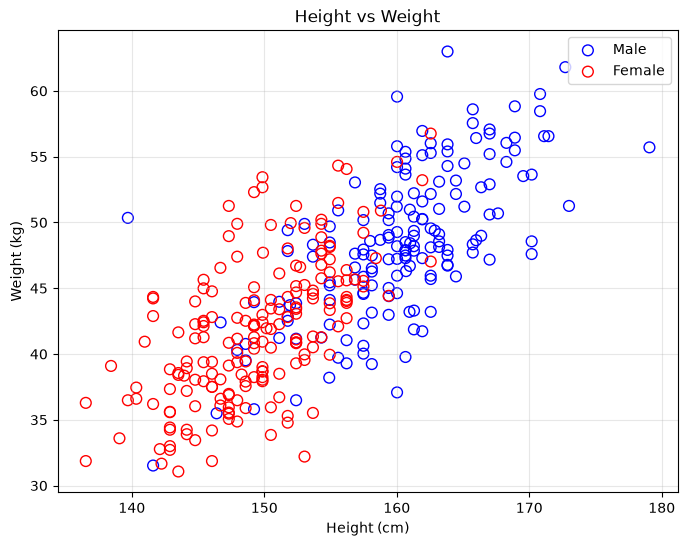

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Male: blue
male = df["male"] == 1
plt.scatter(
    df.loc[male, "height"],
    df.loc[male, "weight"],
    facecolors="none",
    edgecolors="blue",
    marker="o",
    s=60,
    label="Male"
)

# Female: red
female = df["male"] != 1
plt.scatter(
    df.loc[female, "height"],
    df.loc[female, "weight"],
    facecolors="none",
    edgecolors="red",
    marker="o",
    s=60,
    label="Female"
)

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Height vs Weight")
plt.legend()
plt.grid(alpha=0.3)

print(len(df))
plt.show()

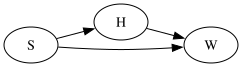

In [3]:
import util
from importlib import reload
# in case we are editinng
reload(util)

# Draw the mediation graph
util.draw_causal_graph(
    edge_list=[
        ("H", "W"),
        ("S", "H"),
        ("S", "W")
    ],
    graph_direction="LR"
)

# the causes are not in the data

# most interventions on height, this will influence weight
# fewer interventions on weight that will influence height





$$
\begin{aligned}
H &= f_H(S)
\\
W &= f_W(H, S)
\end{aligned}
$$

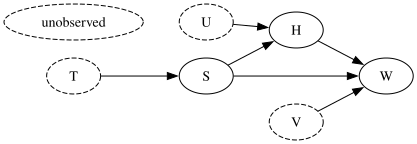

In [5]:
util.draw_causal_graph(
    edge_list=[
        ("H", "W"),
        ("S", "H"),
        ("S", "W"),
        ("V", "W"),
        ("U", "H"),
        ("T", "S")
    ],
    node_props={
        "T": {"style": "dashed"},
        "U": {"style": "dashed"},
        "V": {"style": "dashed"},
        "unobserved": {"style": "dashed"}
    },
    graph_direction="LR"
)

$$
\begin{aligned}
H &= f_H(S, U)
\\
W &= f_W(H, S, V)
\\
S &= f_S(T)
\end{aligned}
$$

unobserved causes, ignorable unless shared, a confound -- https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-04?slide=19

example is temperature in reptiles that as an unknown can impact both sex and weight



In [ ]:
import numpy as np
import pandas as pd

def sim_HW(S, b, a, rng=None):
    # Number of individuals
    N = len(S)

    # Create a random number generator if one wasn't supplied
    if rng is None:
        rng = np.random.default_rng()

    # Simulate height:
    # Female (S=1): mean 150 cm
    # Male   (S=2): mean 160 cm
    # Both groups have a standard deviation of 5 cm (this is U)
    H = np.where(S == 1, 150, 160) + rng.normal(0, 5, N)

    # Simulate weight using group-specific intercepts and slopes:
    # a[S] is the intercept for each individual's group
    # b[S] is the slope for each individual's group
    # Add normally distributed residual noise (SD=5) (this is W)
    # so 2 values for a ; 2 values for b
    W = a[S] + b[S] * H + rng.normal(0, 5, N)

    # Return the simulated data as a DataFrame
    return pd.DataFrame({
        "S": S,
        "H": H,
        "W": W
    })

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("./data/Howell1.csv", sep=";")

df = df[df["age"] >= 18]

# S = 1 female, S = 2 male
S = df["male"].to_numpy().astype(int)
W = df["weight"].to_numpy()

# Convert to zero-based indices for PyMC
S_idx = S

df 

,height,weight,age,male
0,151.765,47.825606,63.0,1
1,139.700,36.485807,63.0,0
2,136.525,31.864838,65.0,0
3,156.845,53.041914,41.0,1
4,145.415,41.276872,51.0,0
...,...,...,...,...
534,162.560,47.031821,27.0,0
537,142.875,34.246196,31.0,0
540,162.560,52.163080,31.0,1
541,156.210,54.062497,21.0,0


In [1]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider())

IntSlider(value=0)

In [26]:
import pymc as pm
import arviz as az
import util
from pathlib import Path 
from importlib import reload
# in case we are editinng
reload(util)

# https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-04?slide=39
# https://youtu.be/F0N4b7K_iYQ?t=1726

with pm.Model() as m_SW:

    # Priors
    alpha = pm.Normal(
        "alpha",
        mu=60,
        sigma=10,
        shape=2
    )

    sigma = pm.Uniform(
        "sigma",
        lower=0,
        upper=10
    )

    # Expected weight for each observation
    mu = alpha[S_idx]

    # Likelihood
    weight = pm.Normal(
        "weight",
        mu=mu,
        sigma=sigma,
        observed=W
    )

    # Sample posterior
    trace = util.sample_or_load(
                lambda: pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        target_accept=0.9,
        random_seed=42
    ), Path(f"chap4_39.trace"))

az.summary(
    trace,
    var_names=["alpha", "sigma"],
    ci_kind="hdi",
    ci_prob=0.89
)

# import arviz_plots as azp

# # women 0 men 1
# azp.plot_dist(
#     trace,
#     var_names=["alpha"],
#     kind="kde"
# )

# with m_SW:
#     pm.sample_posterior_predictive(
#         trace,
#         extend_inferencedata=True,
#         random_seed=42
#     )
# azp.plot_dist(
#     trace,
#     var_names=["alpha"],
#     kind="kde",
#     point_estimate="mean",
#     ci_kind="hdi",
#     ci_prob=0.89
# )
# azp.plot_ppc_dist(
#     trace,
#     var_names=["weight"],
#     kind="kde",
#     num_samples=100
# )

,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha[0],41.85,0.421,41,43,6501,5539,1.00,0.0052,0.0048
alpha[1],48.62,0.431,48,49,7203,6204,1.00,0.0051,0.0046
sigma,5.526,0.212,5.2,5.9,8211,5932,1.00,0.0023,0.0024


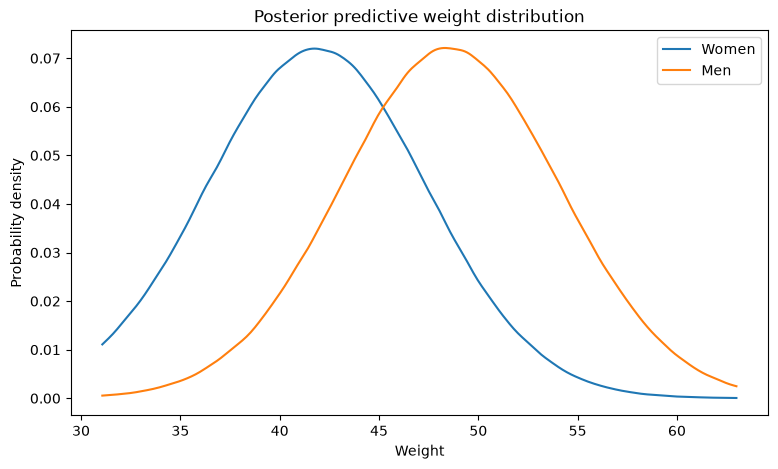

In [11]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np 
# Posterior predictive samples
pp = trace.posterior_predictive["weight"].values

# Combine chains and draws
pp = pp.reshape(-1, pp.shape[-1])

# Split observations by sex
female_weights = pp[:, S_idx == 0].ravel()
male_weights = pp[:, S_idx == 1].ravel()

# KDE
x = np.linspace(W.min(), W.max(), 300)

plt.figure(figsize=(9, 5))

plt.plot(
    x,
    gaussian_kde(female_weights)(x),
    label="Women"
)

plt.plot(
    x,
    gaussian_kde(male_weights)(x),
    label="Men"
)

plt.xlabel("Weight")
plt.ylabel("Probability density")
plt.title("Posterior predictive weight distribution")
plt.legend()
plt.show()

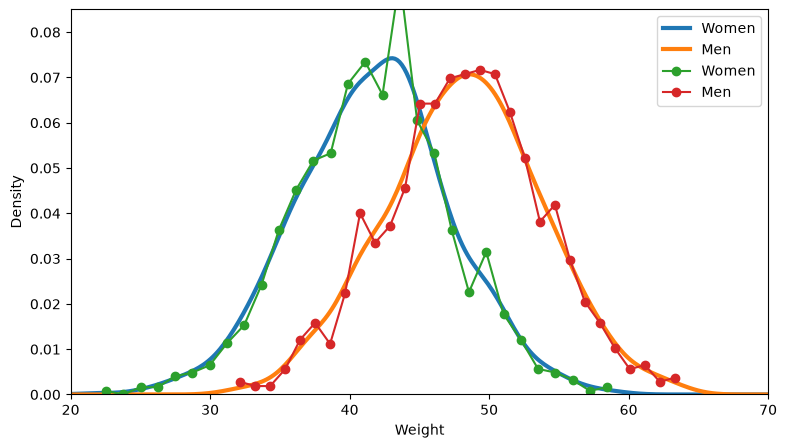

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import arviz_plots as azp

# Extract posterior samples
alpha = trace.posterior["alpha"].values.reshape(-1, 2)
sigma = trace.posterior["sigma"].values.flatten()

# Generate posterior predictive weights
rng = np.random.default_rng(42)

n = 1000

W1 = rng.normal(alpha[:n, 0], sigma[:n])
W2 = rng.normal(alpha[:n, 1], sigma[:n])

#W1 = rng.normal(alpha[:, 0], sigma)
#W2 = rng.normal(alpha[:, 1], sigma)

x = np.linspace(20, 70, 300)

plt.figure(figsize=(9, 5))

plt.plot(x, gaussian_kde(W1)(x), label="Women", linewidth=3)
plt.plot(x, gaussian_kde(W2)(x), label="Men", linewidth=3)

# plt.hist(W1, bins=30, density=True, histtype="step",
#          linewidth=2, label="Women")

# plt.hist(W2, bins=30, density=True, histtype="step",
#          linewidth=2, label="Men")

for weights, label in [(W1, "Women"), (W2, "Men")]:
    density, edges = np.histogram(weights, bins=30, density=True)
    centers = (edges[:-1] + edges[1:]) / 2
    plt.plot(centers, density, marker="o", label=label)

plt.xlim(20, 70)
plt.ylim(0, 0.085)

plt.xlabel("Weight")
plt.ylabel("Density")
plt.legend()
plt.show()



8000


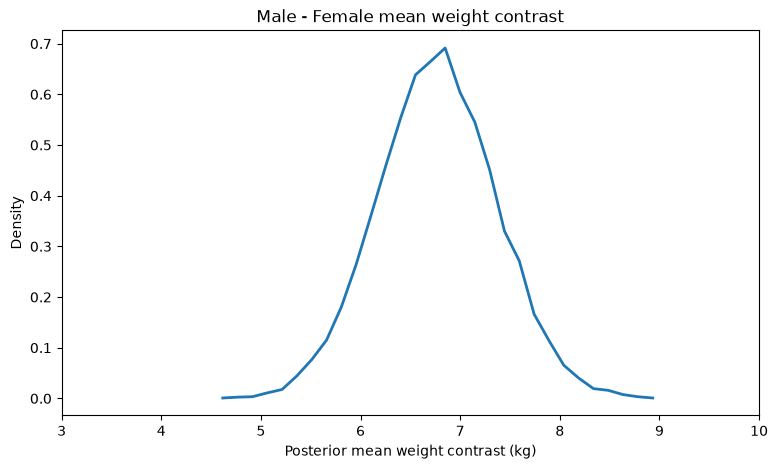

In [22]:
# Extract posterior samples
alpha = trace.posterior["alpha"].values.reshape(-1, 2)

print(len(alpha))

# Male mean - female mean
mu_contrast = alpha[:, 1] - alpha[:, 0]

import numpy as np
import matplotlib.pyplot as plt

density, edges = np.histogram(
    mu_contrast,
    bins=30,
    density=True
)

centers = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(9, 5))

plt.plot(centers, density, linewidth=2)

plt.xlim(3, 10)
plt.xlabel("Posterior mean weight contrast (kg)")
plt.ylabel("Density")
plt.title("Male - Female mean weight contrast")

plt.show()

0.797875


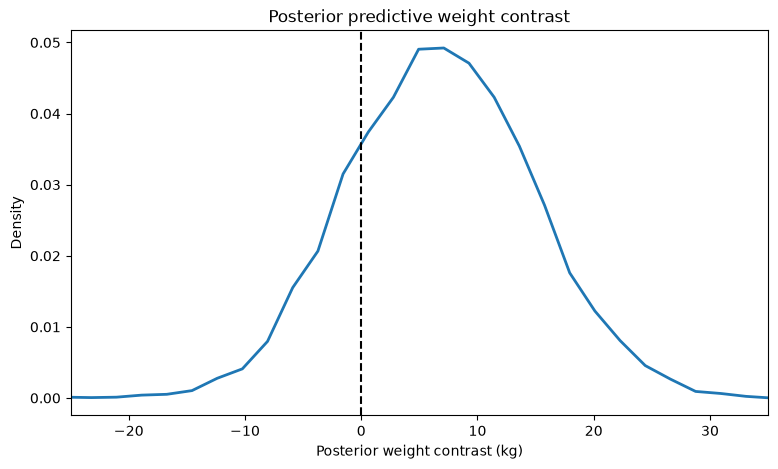

Male heavier:   0.798
Female heavier: 0.202


In [25]:
rng = np.random.default_rng(42)

n = 1000

alpha = trace.posterior["alpha"].values.reshape(-1, 2)
sigma = trace.posterior["sigma"].values.flatten()

# Simulate one individual weight per posterior draw
W1 = rng.normal(alpha[:n, 0], sigma[:n])
W2 = rng.normal(alpha[:n, 1], sigma[:n])

# n = len(sigma)

# W1 = rng.normal(alpha[:, 0], sigma)
# W2 = rng.normal(alpha[:, 1], sigma)

# W_contrast = W2 - W1

# print(np.mean(W_contrast > 0))

# Posterior predictive contrast
W_contrast = W2 - W1

density, edges = np.histogram(
    W_contrast,
    bins=30,
    density=True
)

centers = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(9, 5))
plt.plot(centers, density, linewidth=2)

plt.axvline(0, color="black", linestyle="--")

plt.xlim(-25, 35)
plt.xlabel("Posterior weight contrast (kg)")
plt.ylabel("Density")
plt.title("Posterior predictive weight contrast")

plt.show()

p_male_heavier = np.mean(W_contrast > 0)
p_female_heavier = np.mean(W_contrast < 0)

print(f"Male heavier:   {p_male_heavier:.3f}")
print(f"Female heavier: {p_female_heavier:.3f}")

# see https://github.com/dustinstansbury/statistical-rethinking-2023/blob/main/Lecture%2004%20-%20Categories%20%26%20Curves.ipynb

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("./data/Howell1.csv", sep=";")

df = df[df["age"] >= 18]

# S = 1 female, S = 2 male
S = df["male"].to_numpy().astype(int)
W = df["weight"].to_numpy()
H = df["height"].to_numpy()
Hbar = H.mean()

# Convert to zero-based indices for PyMC
S_idx = S

with pm.Model() as m_SHW:

    alpha = pm.Normal(
        "alpha",
        mu=60,
        sigma=10,
        shape=2
    )

    beta = pm.Uniform(
        "beta",
        lower=0,
        upper=1,
        shape=2
    )

    sigma = pm.Uniform(
        "sigma",
        lower=0,
        upper=10
    )

    mu = alpha[S_idx] + beta[S_idx] * (H - Hbar)

    weight = pm.Normal(
        "weight",
        mu=mu,
        sigma=sigma,
        observed=W
    )

    trace_SHW = util.sample_or_load(
                lambda:pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        target_accept=0.9,
        random_seed=42
    ), Path(f"chap4_58.trace"))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


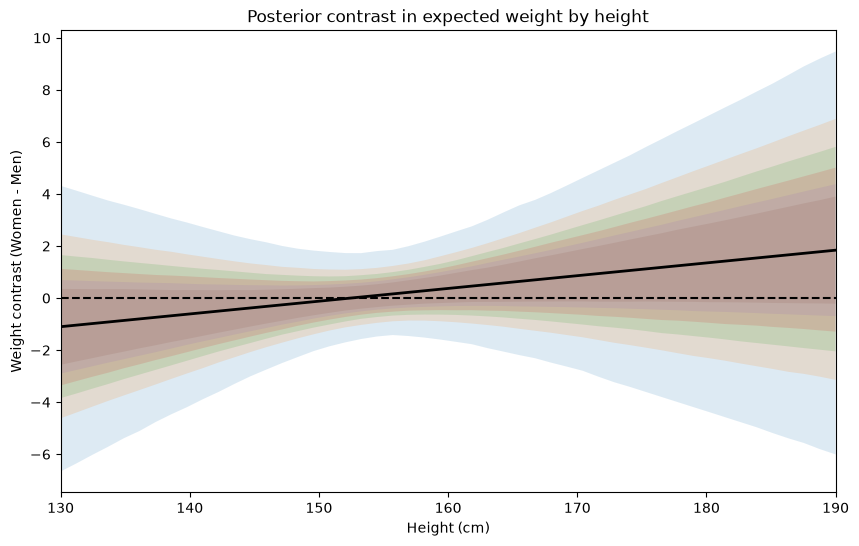

In [28]:
# Extract posterior samples
alpha = trace_SHW.posterior["alpha"].values.reshape(-1, 2)
beta = trace_SHW.posterior["beta"].values.reshape(-1, 2)

# Heights at which to compare women and men
xseq = np.linspace(130, 190, 50)

# Posterior expected weights for women
muF = (
    alpha[:, 0, None]
    + beta[:, 0, None] * (xseq[None, :] - Hbar)
)

# Posterior expected weights for men
muM = (
    alpha[:, 1, None]
    + beta[:, 1, None] * (xseq[None, :] - Hbar)
)

# Difference: women - men
mu_contrast = muF - muM

fig, ax = plt.subplots(figsize=(10, 6))

# Draw widest intervals first
for p in [0.99, 0.90, 0.80, 0.70, 0.60, 0.50]:

    lower = np.quantile(mu_contrast, (1-p)/2, axis=0)
    upper = np.quantile(mu_contrast, (1+p)/2, axis=0)

    ax.fill_between(
        xseq,
        lower,
        upper,
        alpha=0.15
    )

# Posterior mean contrast
ax.plot(
    xseq,
    mu_contrast.mean(axis=0),
    linewidth=2,
    color="black"
)

# Zero difference
ax.axhline(0, linestyle="--", color="black")

ax.set_xlim(130, 190)
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Weight contrast (Women - Men)")
ax.set_title("Posterior contrast in expected weight by height")

plt.show()